# ДЗ 1. ReAct-агент с нуля и цена верного ответа

## Ключ
Использовал не openrouter, поэтому в .env хранится также base_url куда обращается запрос (но если не задан, то по умолчанию в openrouter), также изменены названия моделей

In [48]:
import os, re, sys, json, time, ast, operator, subprocess
from pathlib import Path
from dataclasses import dataclass, field
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field, ValidationError

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass
try:
    from google.colab import userdata
    for _name in ("OPENROUTER_API_KEY", "BASE_URL"):
        try:
            os.environ.setdefault(_name, userdata.get(_name))
        except Exception:
            pass
except ImportError:
    pass

assert os.getenv("OPENROUTER_API_KEY"), "нет ключа: положите его в .env или в Colab Secrets (🔑 слева)"

BASE_URL = (os.getenv("BASE_URL") or "").strip().rstrip("/")
IS_OPENROUTER = not BASE_URL

if IS_OPENROUTER:
    CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
    HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}",
               "HTTP-Referer": "https://postypashki.ru", "X-Title": "agents-course-seminar01"}
    MODELS = {"cheap": "openai/gpt-4o-mini", "mid": "anthropic/claude-haiku-4.5",
              "strong": "anthropic/claude-sonnet-4.6"}
else:
    CHAT_URL = f"{BASE_URL}/chat/completions"
    HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}"}
    MODELS = {"cheap": "gpt-4o-mini", "mid": "claude-haiku-4-5", "strong": "claude-sonnet-4-6"}

print(f"Провайдер: {'OpenRouter' if IS_OPENROUTER else BASE_URL}\nМодели: {MODELS}")

COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = next((p for p in [Path("homework1"), Path("/kaggle/input/datasets/artmakar04/"), Path("/kaggle/input/seminar01-data/data")]
             if (p / "compare_10.jsonl").exists()), Path("homework1"))
TRACES, IMG = Path("traces"), Path("img")
TRACES.mkdir(exist_ok=True)
IMG.mkdir(exist_ok=True)

Провайдер: https://api.dslab.tech/v1
Модели: {'cheap': 'gpt-4o-mini', 'mid': 'claude-haiku-4-5', 'strong': 'claude-sonnet-4-6'}


##  Часть 1. Цена и время
Так как использую не openrouter и в моем сервисе нет подсчета стоимости - то просто решил добавить функцию расчета стоимости, цена за токен - из openrouter согласно первому запросу в гугл

In [9]:
PRICES = {
    "gpt-4o-mini": (0.15, 0.60),
    "claude-haiku-4-5":  (1, 5),
    "claude-sonnet-4-6": (3.0, 15.0),
}

def calc_cost(model, prompt_tokens, completion_tokens):
    inp, out = PRICES.get(model.split("/")[-1], (0.0, 0.0))
    return (prompt_tokens * inp + completion_tokens * out) / 1000000


@dataclass
class Ledger:
    calls: list = field(default_factory=list)

    def add(self, tag, model, usage, seconds=0.0):
        p, c = usage.get("prompt_tokens", 0), usage.get("completion_tokens", 0)
        cost = usage.get("cost") or calc_cost(model, p, c)
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": p, "completion": c,
                           "cost": cost, "seconds": round(seconds, 2)})
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    def table(self):
        df = pd.DataFrame(self.calls)
        return df.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                completion=("completion", "sum"), cost=("cost", "sum"),
                                                seconds=("seconds", "sum")).round(5)

ledger = Ledger()

In [10]:
def post_with_retry(body, attempts=3):
    for attempt in range(attempts):
        r = requests.post(CHAT_URL, json=body, headers=HEADERS, timeout=120)
        if r.status_code == 200:
            return r.json()
        if r.status_code in (429, 500, 502, 503) and attempt < attempts - 1:
            time.sleep(1.5 * (attempt+1))
            continue
        raise RuntimeError(f"HTTP {r.status_code} : {r.text[:5000]}")

In [11]:

def chat(messages, model, tools=None, tag="chat", temperature=None):
    body = {"model": model, "messages": messages}
    if tools:
        body["tools"] = tools
        body["tool_choice"] = "auto"
    if temperature is not None:
        body["temperature"] = temperature
    started = time.perf_counter()
    data = post_with_retry(body)
    ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
    return data["choices"][0]["message"]

In [12]:
msg = chat([{"role": "user", "content": "Ответь одним словом: какого цвета небо?"}], MODELS["strong"], tag="hello")
msg["content"], ledger.calls[-1]

('Голубого.',
 {'tag': 'hello',
  'model': 'claude-sonnet-4-6',
  'prompt': 24,
  'completion': 8,
  'cost': 0.000192,
  'seconds': 1.35})

In [13]:
question = [{"role": "user", "content": "Объясни в трёх предложениях, что такое контекстное окно языковой модели. Включи максимально подробное объяснение"}]
answers = {name: chat(question, model, tag="window")["content"] for name, model in MODELS.items()}
ledger.table().loc["window"]

,calls,prompt,completion,cost,seconds
model,,,,,
claude-haiku-4-5,1,48,268,0.00139,3.69
claude-sonnet-4-6,1,48,464,0.00710,11.59
gpt-4o-mini,1,35,114,0.00007,2.96


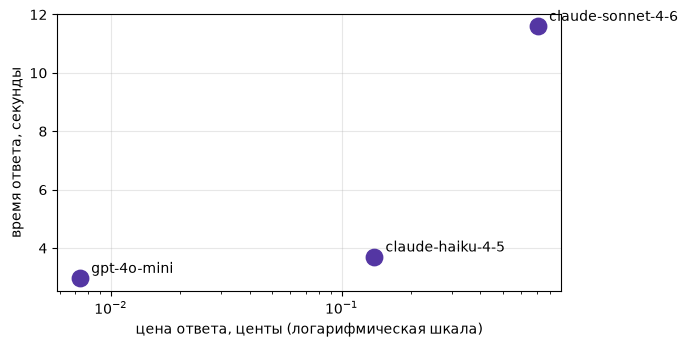

In [14]:
def cost_time_chart(tag):
    df = pd.DataFrame([c for c in ledger.calls if c["tag"] == tag])
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.scatter(df["cost"] * 100, df["seconds"], s=140, color=COLORS["violet"])
    for _, r in df.iterrows():
        ax.annotate(r["model"], (r["cost"] * 100, r["seconds"]), xytext=(8, 4), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("цена ответа, центы (логарифмическая шкала)")
    ax.set_ylabel("время ответа, секунды")
    ax.grid(alpha=0.3)
    return fig

cost_time_chart("window");

## Часть 2. Ответ и схема

In [16]:
class Answer(BaseModel):
    reasoning: str = Field(description="ход решения в два-три предложения")
    final: str = Field(description="только итоговый ответ: число, короткая фраза или слово")

SCHEMA_PROMPT = "Отвечай строго одним JSON-объектом по этой схеме, без текста вокруг, строки в одну линию, без лишних отступов, \t, \n:\n{schema}"

def json_from(text):
    m = re.search(r"\{.*\}", text or "", re.S)
    if not m:
        raise ValueError("в ответе нет JSON")
    return json.loads(m.group(0), strict=False)

In [17]:
def ask_structured(question, model, schema=Answer, attempts=3):
    messages = [
        {"role": "system", "content": SCHEMA_PROMPT.format(schema=json.dumps(schema.model_json_schema(), ensure_ascii=False))},
        {"role": "user", "content": question}
    ]
    for _ in range(attempts):
        msg = chat(messages, model, tag="struct")
        try:
            return schema.model_validate(json_from(msg["content"]))
        except (ValidationError, ValueError) as e:
            messages += [msg, {"role": "user", "content": f"Ответ не прошел проверку на структуру: {e}. Верни ответ по строгой JSON схеме"}]
    raise ValueError("Модель не справилась")

In [53]:
def load_tasks(name):
    with open(name, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

## Часть 3. Функции для сравнения моделей

In [ ]:
def normalize(text):
    text = re.sub(r"[^\w\s]", " ", str(text).lower().replace(",", ""))
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())


def is_correct(task, answer):
    if task["source"] == "gsm8k":
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(answer).replace(",", ""))
        return bool(nums) and abs(float(nums[-1]) - float(task["answer"])) < 1e-6
    return normalize(task["answer"]) in normalize(answer)

def summary(config, model, n, correct, cost, steps, seconds=0.0):
    return {"config": config, "model": model.split("/")[-1], "n": n, "accuracy": round(correct / n, 2),
            "cost_per_task": round(cost / n, 5), "cost_per_correct": round(cost / correct, 5) if correct else float("inf"),
            "avg_steps": round(steps, 2), "avg_seconds": round(seconds, 1)}

def compare_models(tasks, models):
    rows = []
    for name, model in models.items():
        before, correct, started = ledger.total, 0, time.perf_counter()
        for task in tasks:
            try:
                correct += is_correct(task, ask_structured(task["question"], model).final)
            except Exception:
                pass
        rows.append(summary("без инструментов, JSON", model, len(tasks), correct, ledger.total - before, 1,
                            (time.perf_counter() - started) / len(tasks)))
    return pd.DataFrame(rows)

def compare_chart(df):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
    axes[0].bar(df["model"], df["accuracy"] * 100, color=COLORS["violet"])
    axes[0].set_ylabel("доля верных, %")
    axes[0].set_ylim(0, 105)
    axes[1].bar(df["model"], df["cost_per_correct"] * 100, color=COLORS["amber"])
    axes[1].set_ylabel("цена верного ответа, центы")
    axes[2].bar(df["model"], df["avg_seconds"], color=COLORS["teal"])
    axes[2].set_ylabel("секунд на задачу")
    for ax in axes:
        ax.tick_params(axis="x", labelrotation=12)
        ax.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    return fig

## Часть 4. Цикл ReAct

In [21]:
TOOLS = {}

def register(fn, args_model, description):
    TOOLS[fn.__name__] = {"fn": fn, "args": args_model, "schema": {"type": "function", "function": {
        "name": fn.__name__, "description": description, "parameters": args_model.model_json_schema()}}}

OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv,
       ast.Pow: operator.pow, ast.USub: operator.neg, ast.Mod: operator.mod}

def evaluate(node):
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in OPS:
        return OPS[type(node.op)](evaluate(node.left), evaluate(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in OPS:
        return OPS[type(node.op)](evaluate(node.operand))
    raise ValueError("допустимы только числа и арифметика")

class CalcArgs(BaseModel):
    expr: str = Field(description="арифметическое выражение, например 17*23+5")

def calculator(expr: str) -> str:
    try:
        val = evaluate(ast.parse(expr.replace(",", "."), mode="eval").body)
        return str(int(val)) if float(val).is_integer() else f"{val:.4f}".rstrip("0")
    except Exception as e:
        return f"ошибка вычисления: {e}"

register(calculator, CalcArgs, "Считает арифметическое выражение: числа, скобки, + - * / ** %")

In [23]:
SYSTEM = ("Ты отвечаешь на короткие вопросы о недавних событиях (2025-2026 годы). Своей памяти об этих событиях не верь: "
          "сначала найди факт инструментами.Вопрос на русском ищи в русской Википедии (lang='ru') и отвечай по-русски, в написании оттуда. "
          "Не повторяй вызов с теми же аргументами. Если нужно посчитать, вызывай calculator или python_exec. "
          "Когда ответ готов, напиши его последней строкой в формате FINAL: <ответ>. В FINAL только короткий ответ из "
          "источника: имя, число, название или дату, без пояснений. Если найти не удалось, напиши FINAL: unknown.")

@dataclass
class Run:
    question: str
    answer: str
    steps: int
    messages: list
    cost: float = 0.0
    seconds: float = 0.0

def looped(seen, calls):
    keys = [(c["function"]["name"], c["function"]["arguments"]) for c in calls]
    repeated = any(k in seen for k in keys)
    seen.update(keys)
    return repeated

def finish(model, messages, step):
    del messages[-1]
    messages.append({"role": "user", "content": "Инструменты больше недоступны. Ответь по тому, что уже известно, последней строкой FINAL: <ответ>."})
    msg = chat(messages, model, tag="agent")
    messages.append(msg)
    return msg.get("content") or "", step + 1

In [24]:
def run_tool(call):
    name = call["function"]["name"]

    try:
        spec = TOOLS[name]
        args = spec["args"].model_validate_json(call["function"]["arguments"])
        result = spec["fn"](**args.model_dump())
    except Exception as e:
        result = f"НЕ удалось вызвать инструмент {name}: {e}"
    return {"role": "tool", "tool_call_id" : call["id"], "content": str(result)[:2000]}


In [25]:
def agent_loop(messages, model, tool_names, max_steps):
    seen = set()
    for step in range(1, max_steps + 1):
        msg = chat(messages, model, tools=[TOOLS[n]["schema"] for n in tool_names] or None, tag='agent')
        messages.append(msg)
        calls = msg.get("tool_calls") or []

        if not calls:
            return msg.get("content") or "", step
        if looped(seen, calls) or step == max_steps:
            return finish(model, messages, step)

        messages += [run_tool(c) for c in calls]


In [26]:
def agent(question, model, tool_names, max_steps=8):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    before, started = ledger.total, time.perf_counter()
    answer, steps = agent_loop(messages, model, tool_names, max_steps)
    return Run(question, answer, steps, messages, ledger.total - before, time.perf_counter() - started)

def show_trace(run):
    for m in run.messages[1:]:
        calls = "; ".join(f"{c['function']['name']}{c['function']['arguments']}" for c in m.get("tool_calls") or [])
        text = " ".join((m.get("content") or "").split())[:180]
        print(f"{m['role']:9s}| {text} {calls}")
    print(f"шагов: {run.steps}, цена: {run.cost * 100:.3f} ¢, время: {run.seconds:.1f} c")

## Часть 5. Инструменты

In [29]:
WIKI_HEADERS = {"User-Agent": "agents-course-seminar01/1.0 (https://postypashki.ru; educational project)"}

def wiki(params, attempts=3, lang="en"):
    for attempt in range(attempts):
        r = requests.get(f"https://{lang}.wikipedia.org/w/api.php", params={**params, "format": "json"},
                         headers=WIKI_HEADERS, timeout=15)
        if r.status_code == 200 and r.headers.get("content-type", "").startswith("application/json"):
            return r.json()["query"]
        time.sleep(1.0 + attempt)
    raise RuntimeError(f"Википедия ответила {r.status_code}")

class SearchArgs(BaseModel):
    query: str = Field(description="короткий поисковый запрос: имя, название, термин")
    lang: str = Field(default="en", description="язык Википедии: 'en' (по умолчанию) или 'ru' для вопросов на русском")

class ExecArgs(BaseModel):
    code: str = Field(description="код на Python; результат надо напечатать через print")

In [30]:
def web_search(query: str, lang: str = "en") -> str:
    hits = wiki({"action": "query", "list": "search", "srsearch": query, "srlimit": 3}, lang=lang).get("search", [])
    if not hits:
        return "No data"
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "exintro": 1, "titles": hits[0]["title"]}, lang=lang)["pages"]
    text = " ".join(next(iter(pages.values())).get("extract", "").split())
    others = ", ".join(h["title"] for h in hits[1:])
    return f"[{hits[0]['title']}] {text[:1500]}" + (f" | другие статьи: {others}" if others else "")

In [ ]:
def python_exec(code: str) -> str:
    try:
        r = subprocess.run([sys.executable, "-I", "-c", code], capture_output=True, text=True, timeout=5)
    except subprocess.TimeoutExpired:
        return "Код превысил 5 сек"
    out = (r.stdout + r.stderr).strip()
    return out[:5000] if out else "Код исполнился но результат пустой"


In [33]:
register(web_search, SearchArgs, "Ищет статью в Википедии (английская и русская) и возвращает её вступление и названия"
         "еще же статей в выдаче, если есть")
register(python_exec, ExecArgs, "Выполняет код на Python в отдельном процессе и возвращает то, что он напечатал")


In [34]:
class PageFindArgs(BaseModel):
    title: str = Field(description="точное название статьи Википедии, например '2026 in Japan' или 'Гран-при Италии 2026 года'")
    keywords: str = Field(description="2-5 характерных слов из вопроса: имена, места, событие; не одни даты")
    lang: str = Field(default="en", description="язык Википедии: 'en' (по умолчанию) или 'ru'")

def page_find(title: str, keywords: str, lang: str = "en") -> str:
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "titles": title, "redirects": 1}, lang=lang)["pages"]
    page = next(iter(pages.values()))
    text = page.get("extract", "")
    if not text:
        return f"No data: статьи '{title}' нет, найдите точное название через web_search"
    words = [w for w in re.findall(r"\w+", keywords.lower()) if len(w) > 2]
    need = max(1, (len(words) + 1) // 2)
    lines = [l.strip() for l in text.splitlines() if l.strip()]
    scored = sorted((-sum(w in l.lower() for w in words), i, l[:400]) for i, l in enumerate(lines))
    hits = [l for s, _, l in scored if -s >= need][:6]
    return f"[{page.get('title', title)}]\n" + "\n".join(hits) if hits else "No data: ключевые слова на странице не найдены, попробуйте другие"

register(page_find, PageFindArgs, "Читает полный текст статьи Википедии и возвращает только строки с ключевыми словами. "
         "Для длинных обзорных статей ('2026 in <страна>', статья о сезоне или этапе), где факт лежит в теле, а не во "
         "вступлении. Чтобы найти, какая статья существует, используй инструмент web_search")

In [83]:
class TavilyArgs(BaseModel):
    query: str = Field(description="поисковый запрос обычными словами, 3-8 слов, например 'Singapore Grand Prix 2026 winner'")


def tavily_post(body):
    key = os.getenv("TAVILY_API_KEY")
    if not key:
        raise RuntimeError("нет TAVILY_API_KEY в .env")
    r = requests.post("https://api.tavily.com/search", json=body, headers={"Authorization": f"Bearer {key}"}, timeout=30)
    if r.status_code != 200:
        raise RuntimeError(f"Tavily ответил {r.status_code}: {r.text[:200]}")
    return r.json()


def tavily_search(query: str) -> str:
    # include_answer=False: агент читает сами фрагменты источников, а не готовый ответ другой модели
    data = tavily_post({"query": query, "search_depth": "basic", "max_results": 5, "include_answer": False})
    results = data.get("results") or []
    if not results:
        return "No data"
    return "\n".join(f"- {r.get('title', '')} | {r.get('url', '')} | {' '.join(str(r.get('content', '')).split())[:400]}"
                     for r in results)


register(tavily_search, TavilyArgs, "Ищет по всему интернету через Tavily: новости, официальные сайты, свежие статьи. "
         "Возвращает до 5 результатов: заголовок, ссылку и фрагмент текста. Зови, когда в Википедии ничего нет, "
         "особенно для событий последних недель")

## Часть 6. Прогон, трейсы и деньги

In [84]:
def final_answer(text):
    m = re.search(r"FINAL:\s*(.+)", text or "")
    return m.group(1).strip() if m else (text or "").strip()

def run_tasks(tasks, model, tool_names, config):
    folder = TRACES / config / model.split("/")[-1]
    folder.mkdir(parents=True, exist_ok=True)
    rows = []
    for task in tasks:
        try:
            run = agent(task["question"], model, tool_names)
        except Exception as e:
            run = Run(task["question"], f"ошибка: {e}", 0, [])
        ok = is_correct(task, final_answer(run.answer))
        rows.append({"config": config, "model": model.split("/")[-1], "id": task["id"], "source": task["source"],
                     "correct": ok, "steps": run.steps, "tool_calls": sum(m["role"] == "tool" for m in run.messages),
                     "cost": run.cost, "seconds": round(run.seconds, 1), "answer": final_answer(run.answer)[:60], "gold": task["answer"]})
        (folder / f"{task['id']}.json").write_text(json.dumps({"task": task, "answer": run.answer, "correct": ok, "cost": run.cost,
                                                              "messages": run.messages}, ensure_ascii=False, indent=1), encoding="utf-8")
    return pd.DataFrame(rows)

def report(results):
    rows = [summary(config, model, len(df), int(df["correct"].sum()), df["cost"].sum(), df["steps"].mean(), df["seconds"].mean())
            for (config, model), df in results.groupby(["config", "model"])]
    return pd.DataFrame(rows).sort_values("cost_per_task").reset_index(drop=True)

def money_chart(table, path="img/money_quality.png"):
    fig, ax = plt.subplots(figsize=(8, 5))
    for _, r in table.iterrows():
        color = COLORS["red"] if "каскад" in r["config"] else COLORS["amber"] if "sonnet" in r["model"] else COLORS["violet"]
        ax.scatter(r["cost_per_task"] * 100, r["accuracy"] * 100, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (r["cost_per_task"] * 100, r["accuracy"] * 100),
                    fontsize=8, xytext=(6, 4), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("цена задачи, центы (логарифмическая шкала)")
    ax.set_ylabel("доля верных ответов, %")
    ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig

def steps_chart(results):
    g = results.groupby("config").agg(steps=("steps", "mean"), tool_calls=("tool_calls", "mean"), seconds=("seconds", "mean"))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    g[["steps", "tool_calls"]].plot.bar(ax=axes[0], color=[COLORS["violet"], COLORS["teal"]], rot=12)
    axes[0].set_ylabel("в среднем на задачу")
    g["seconds"].plot.bar(ax=axes[1], color=COLORS["amber"], rot=12)
    axes[1].set_ylabel("секунд на задачу")
    for ax in axes:
        ax.grid(alpha=0.3, axis="y")
        ax.set_xlabel("")
    fig.tight_layout()
    return fig


## Часть 7. Каскад

In [85]:
class Confident(BaseModel):
    reasoning: str = Field(description="ход решения в два-три предложения")
    final: str = Field(description="только итоговый ответ")
    confidence: float = Field(description="честная уверенность в ответе от 0 до 1")

MEMO = {}

def confident_answer(task, model):
    key = (task["id"], model)
    if key not in MEMO:
        before = ledger.total
        try:
            ans = ask_structured(task["question"], model, Confident)
            MEMO[key] = {"final": ans.final, "confidence": ans.confidence, "correct": is_correct(task, ans.final)}
        except Exception:
            MEMO[key] = {"final": "", "confidence": 0.0, "correct": False}
        MEMO[key]["cost"] = ledger.total - before
    return dict(MEMO[key])

In [86]:
def cascade(task, threshold):
    cheap = confident_answer(task, MODELS['cheap'])
    if cheap["confidence"] >= threshold:
        return {**cheap, "escalated": False}
    strong = confident_answer(task, MODELS['strong'])
    return {**strong, "cost": cheap["cost"] + strong["cost"], "escalated": True}

In [87]:
def cascade_sweep(tasks, thresholds):
    rows = []
    for th in thresholds:
        outs = [cascade(t, th) for t in tasks]
        rows.append({"threshold": th, "accuracy": sum(o["correct"] for o in outs) / len(outs),
                     "cost_per_task": sum(o["cost"] for o in outs) / len(outs),
                     "escalated": sum(o["escalated"] for o in outs) / len(outs)})
    df = pd.DataFrame(rows)
    df["cost_per_correct"] = df["cost_per_task"] / df["accuracy"].replace(0, float("nan"))
    return df.round(5)

def cascade_chart(df):
    fig, ax = plt.subplots(figsize=(7, 4.2))
    ax.plot(df["cost_per_task"] * 100, df["accuracy"] * 100, marker="o", color=COLORS["red"])
    for _, r in df.iterrows():
        ax.annotate(f"порог {r['threshold']}, наверх {r['escalated']:.0%}", (r["cost_per_task"] * 100, r["accuracy"] * 100),
                    xytext=(6, -12), textcoords="offset points", fontsize=8)
    ax.set_xlabel("цена задачи, центы")
    ax.set_ylabel("доля верных, %")
    ax.grid(alpha=0.3)
    return fig

def confidence_chart(tasks, model):
    df = pd.DataFrame([confident_answer(t, model) for t in tasks])
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.hist(df[df["correct"]]["confidence"], bins=10, range=(0, 1), alpha=0.7, color=COLORS["teal"], label="верные")
    ax.hist(df[~df["correct"]]["confidence"], bins=10, range=(0, 1), alpha=0.7, color=COLORS["red"], label="неверные")
    ax.set_xlabel("заявленная уверенность")
    ax.set_ylabel("задач")
    ax.legend()
    ax.grid(alpha=0.3)
    return fig

In [99]:
def unsure(row):
    answer = str(row.get("answer", ""))
    return (normalize(answer) in ("", "unknown")
            or answer.startswith("ошибка")
            or bool(row.get("forced", False)))

In [89]:
def agent_cascade(cheap_df, mid_df, config="каскад: дешёвая → средняя"):
    """Собирается из уже сделанных прогонов: результат тот же, что при последовательном запуске, без повторных трат."""
    mid = mid_df.set_index("id")
    rows = []
    for _, c in cheap_df.iterrows():
        if unsure(c) and c["id"] in mid.index:
            m = mid.loc[c["id"]]
            rows.append({**m.to_dict(), "id": c["id"], "config": config, "model": "mini → haiku", "escalated": True,
                         "cost": c["cost"] + m["cost"], "steps": c["steps"] + m["steps"],
                         "seconds": c["seconds"] + m["seconds"], "tool_calls": c["tool_calls"] + m["tool_calls"]})
        else:
            rows.append({**c.to_dict(), "config": config, "model": "mini → haiku", "escalated": False})
    return pd.DataFrame(rows)

In [90]:
EMPTY = ("no data", "нет данных", "не удалось вызвать", "ошибка")


def classify_failure(trace):
    """Категория провала по трейсу: четыре категории из задания."""
    gold, answer = normalize(trace["task"]["answer"]), normalize(final_answer(trace["answer"]))
    words = gold.split()
    if words and answer not in ("", "unknown") and sum(w in answer.split() for w in words) / len(words) >= 0.6:
        return "ответ верный, но не прошёл проверку"
    results = [m.get("content") or "" for m in trace["messages"] if m["role"] == "tool"]
    if any(f" {gold} " in f" {normalize(r)} " for r in results):
        return "нашёл, но модель не прочла"
    if results and not all(r.strip().lower().startswith(EMPTY) for r in results):
        return "нашёл не то"
    return "поиск не нашёл"

def failures(config, model):
    rows = []
    for p in sorted((TRACES / config / model.split("/")[-1]).glob("*.json")):
        t = json.loads(p.read_text(encoding="utf-8"))
        if not t["correct"]:
            rows.append({"id": t["task"]["id"], "category": classify_failure(t), "question": t["task"]["question"][:90],
                         "gold": t["task"]["answer"], "answer": final_answer(t["answer"])[:60],
                         "trace": str(p)})
    return pd.DataFrame(rows)

## Часть 7. Тестирование на собственном наборе данных

In [91]:
tasks = load_tasks("fresh.jsonl")


In [92]:
len(tasks), tasks[len(tasks) - 1]

(40,
 {'id': 'f1-39',
  'source': 'f1',
  'question': 'Кого заблокировал Льюис Хэмилтон в третьем сегменте квалификации Гран-при Венгрии 2026 года, получив штраф в три позиции?',
  'answer': 'Пиастри',
  'evidence': 'Льюис Хэмилтон был оштрафован на три позиции на стартовой решётке за блокировку Оскара Пиастри во время третьего сегмента квалификации.',
  'page': 'Гран-при Венгрии 2026 года',
  'url': 'https://ru.wikipedia.org/wiki/Гран-при_Венгрии_2026_года'})

In [93]:
print(web_search("Гран-при Италии 2026", lang="ru")[:300], "\n")
print(page_find("Гран-при Италии 2026 года", "Гасли поул-позицию", lang="ru"), "\n")
if os.getenv("TAVILY_API_KEY"):
    print(tavily_search("Italian Grand Prix 2026 pole position Gasly"))

[Гран-при Италии 2026 года] Гран-при Италии 2026 года (официально итал. Formula 1 Pirelli Gran Premio d'Italia 2026) — тринадцатый этап чемпионата мира Формулы-1 2026 года. Прошёл с 4 по 6 сентября на Национальном автодроме Монца в Монце, Италия. Это был 77-й Гран-при Италии в рамках чемпионатов мир 

[Гран-при Италии 2026 года]
Пьер Гасли из команды Alpine завоевал свою первую поул-позицию в карьере. 

- Italian GP Qualifying Results: Gasly Takes Shock Monza Pole | https://www.formuladream.app/blog/italian-gp-2026-qualifying-results | Free, no subscription, no ads, independent. Not affiliated with Formula 1. Get the Formula Dream app ## Frequently asked questions ### Who is on pole for the 2026 Italian Grand Prix? Pierre Gasly, for Alpine, with a 1:21.786. It is his first pole position in Formula 1 and the first in Alpine's history since the team took that name in 2021. ### By how much did Gasly take pole at Monza? 0.060 second
- 2026 Italian GP Qualifying: Pierre Gasly crosses the li

In [94]:
f1 = [t for t in tasks if t["source"] == "f1"]
run = agent(f1[0]["question"], MODELS["cheap"], ["web_search", "page_find", "tavily_search", "calculator", "python_exec"])
show_trace(run)

user     | Кто завоевал первую в карьере поул-позицию на Гран-при Италии 2026 года в Монце? 
assistant|  web_search{"lang":"ru","query":"Гран-при Италии 2026 поул-позиция"}
tool     | [Формула-1 в сезоне 2026] Сезон 2026 года — сезон Формулы-1, в рамках которого проводится 77-й чемпионат мира по автогонкам в классе «Формула-1». Международной автомобильной федера 
assistant|  page_find{"keywords":"Гран-при Италии 2026 поул-позиция","lang":"ru","title":"Гран-при Италии 2026 года"}
tool     | [Гран-при Италии 2026 года] Гран-при Италии 2026 года (официально итал. Formula 1 Pirelli Gran Premio d'Italia 2026) — тринадцатый этап чемпионата мира Формулы-1 2026 года. Прошёл  
assistant|  tavily_search{"query":"поул-позиция Гран-при Италии 2026"}
tool     | - Гасли сенсационно завоевал поул-позицию на Гран-при Италии "Формулы-1" - РИА Новости Спорт, 05.09.2026 | https://ria.ru/20260905/formula-1-2115717271.html | Также в первую десятк 
assistant| FINAL: Пьер Гасли 
шагов: 4, цена: 0.076 ¢, врем

In [95]:
TOOLS_SEARCH = ["web_search"]                                               # базовый агент с семинара
TOOLS_PAGE = ["web_search", "page_find", "calculator", "python_exec"]       # поиск + чтение страницы
CONFIGS = {"без инструментов": [], "только поиск": TOOLS_SEARCH, "поиск + страница": TOOLS_PAGE}
if os.getenv("TAVILY_API_KEY"):
    CONFIGS["поиск + страница + Tavily"] = TOOLS_PAGE + ["tavily_search"]
else:
    print("TAVILY_API_KEY нет: конфигурация с Tavily пропущена")

SAMPLE = None
if SAMPLE:
    import random
    rest = [t for t in tasks if t["source"] != "f1"]
    random.Random(7).shuffle(rest)
    tasks_run = f1 + rest[:SAMPLE - len(f1)]
else:
    tasks_run = tasks
ledger.budget = 5.0
list(CONFIGS), len(tasks_run)

(['без инструментов',
  'только поиск',
  'поиск + страница',
  'поиск + страница + Tavily'],
 40)

In [96]:
frames = [run_tasks(tasks_run, MODELS["strong"], [], "без инструментов")]
frames += [run_tasks(tasks_run, MODELS["cheap"], tools, config) for config, tools in CONFIGS.items()]
cheap = pd.concat(frames[1:], ignore_index=True)
round(ledger.total, 3)

2.218

In [97]:
# лучший набор инструментов дешёвой модели
acc = cheap[cheap["config"] != "без инструментов"].groupby("config").agg(acc=("correct", "mean"), cost=("cost", "mean"))
BEST = acc.sort_values(["acc", "cost"], ascending=[False, True]).index[0]
frames.append(run_tasks(tasks_run, MODELS["mid"], CONFIGS[BEST], BEST))
BEST, round(ledger.total, 3)

('поиск + страница + Tavily', 3.109)

In [103]:
results = pd.concat(frames, ignore_index=True)
casc = agent_cascade(results[(results["config"] == BEST) & (results["model"] == "gpt-4o-mini")],
                     results[(results["config"] == BEST) & (results["model"] == "claude-haiku-4.5")])
homework = pd.concat([results, casc], ignore_index=True)
homework.to_csv("results_raw.csv", index=False)
table = report(homework)
print("в каскаде к средней модели ушло", f"{casc['escalated'].mean():.0%}")
table

в каскаде к средней модели ушло 0%


,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,без инструментов,gpt-4o-mini,40,0.00,0.00005,inf,1.00,1.2
1,каскад: дешёвая → средняя,mini → haiku,40,0.82,0.00140,0.00170,5.18,13.0
2,поиск + страница + Tavily,gpt-4o-mini,40,0.82,0.00140,0.00170,5.18,13.0
3,поиск + страница,gpt-4o-mini,40,0.35,0.00173,0.00493,7.02,18.3
4,только поиск,gpt-4o-mini,40,0.05,0.00207,0.04135,8.38,22.4
5,без инструментов,claude-sonnet-4-6,40,0.05,0.01568,0.31362,1.00,15.9
6,поиск + страница + Tavily,claude-haiku-4-5,40,0.78,0.02230,0.02877,3.40,11.2


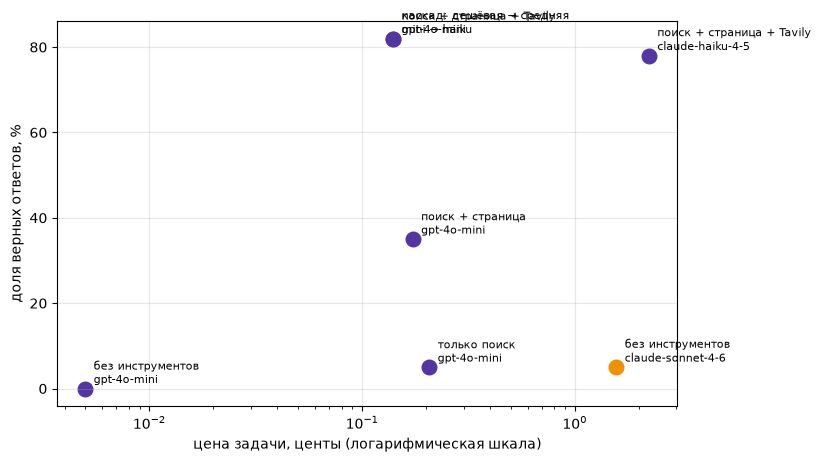

In [110]:
money_chart(table, "img/homework.png");

In [111]:
# доля верных отдельно на вопросах с числовым ответом и с ответом-словом (фамилия, название)
kind = {t["id"]: "число или дата" if re.search(r"\d", t["answer"]) else "слово" for t in tasks}
homework.assign(kind=homework["id"].map(kind)).pivot_table(
    index=["config", "model"], columns="kind", values="correct", aggfunc="mean").round(2)

kind                                         слово  число или дата
config                    model                                   
без инструментов          claude-sonnet-4-6   0.00            0.08
                          gpt-4o-mini         0.00            0.00
каскад: дешёвая → средняя mini → haiku        0.86            0.81
поиск + страница          gpt-4o-mini         0.43            0.31
поиск + страница + Tavily claude-haiku-4-5    0.71            0.81
                          gpt-4o-mini         0.86            0.81
только поиск              gpt-4o-mini         0.07            0.04

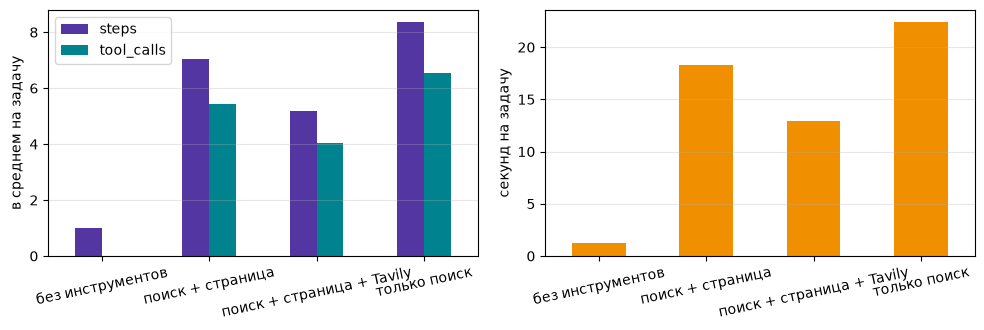

In [112]:
steps_chart(homework[homework["model"] == "gpt-4o-mini"]);

## Часть 8. Разбор ошибок

In [105]:
fails = failures(BEST, MODELS["cheap"])
fails["category"].value_counts()

category
нашёл не то                   5
нашёл, но модель не прочла    2
Name: count, dtype: int64

In [106]:
fails.groupby("category").head(2)

,id,category,question,gold,answer,trace
0,f1-13,нашёл не то,На сколько позиций на стартовой решётке был ош...,35,10,traces/поиск + страница + Tavily/gpt-4o-mini/f...
1,f1-17,"нашёл, но модель не прочла",Каким был классифицирован Оливер Берман на Гра...,19,unknown,traces/поиск + страница + Tavily/gpt-4o-mini/f...
2,f1-18,нашёл не то,С кем столкнулся Карлос Сайнс на Гран-при Ниде...,Албон,Лиам Лоусон,traces/поиск + страница + Tavily/gpt-4o-mini/f...
4,f1-25,"нашёл, но модель не прочла",Каким квалифицировался Изак Хаджар на Гран-при...,9,6 место,traces/поиск + страница + Tavily/gpt-4o-mini/f...


In [108]:
t = json.loads(Path(fails.iloc[0]["trace"]).read_text(encoding="utf-8"))
steps = sum(m["role"] == "assistant" for m in t["messages"])
show_trace(Run(t["task"]["question"], t["answer"], steps, t["messages"], t["cost"]))

user     | На сколько позиций на стартовой решётке был оштрафован Лиам Лоусон на Гран-при Италии 2026 года за превышение лимита на элементы силовой установки? 
assistant|  page_find{"keywords":"Лиам Лоусон Гран-при Италии 2026","lang":"ru","title":"Гран-при Италии 2026 года"}
tool     | [Гран-при Италии 2026 года] Гран-при Италии 2026 года (официально итал. Formula 1 Pirelli Gran Premio d'Italia 2026) — тринадцатый этап чемпионата мира Формулы-1 2026 года. Прошёл  
assistant|  tavily_search{"query":"Лиам Лоусон штраф стартовая решётка Гран-при Италии 2026"}
tool     | - ОФИЦИАЛЬНО. Пилот Макларен потеряет 3 места на ... | https://sport.ua/news/904552-ofitsialno-pilot-maklaren-poteryaet-3-mesta-na-starte-gran-pri-italii | Пилот Макларена Оскар Пи 
assistant|  web_search{"lang":"ru","query":"Лиам Лоусон штраф стартовая решётка Гран-при Италии 2026"}
tool     | НЕ удалось вызвать инструмент web_search: 'query' 
assistant|  page_find{"keywords":"Лиам Лоусон","lang":"ru","title":"2026 в Фор

In [113]:
t = json.loads(Path(fails.iloc[1]["trace"]).read_text(encoding="utf-8"))
steps = sum(m["role"] == "assistant" for m in t["messages"])
show_trace(Run(t["task"]["question"], t["answer"], steps, t["messages"], t["cost"]))

user     | Каким был классифицирован Оливер Берман на Гран-при Венгрии 2026 года после 5-секундного штрафа за игнорирование синих флагов? 
assistant|  web_search{"lang":"ru","query":"Оливер Берман Гран-при Венгрии 2026"}
tool     | НЕ удалось вызвать инструмент web_search: 'query' 
assistant|  tavily_search{"query":"Оливер Берман Гран-при Венгрии 2026"}
tool     | - Авария Оливера Бермана на гран при Японии 2026 💥 ... | https://www.instagram.com/p/DXcCVgrlzdg | on April 22, 2026: Оливера Бермана на гран при Японии 2026. Гран При Венгрии и Гр 
assistant|  web_search{"lang":"ru","query":"Оливер Берман Гран-при Венгрии 2026 результат после штрафа"}
tool     | [Формула-1 в сезоне 2026] Сезон 2026 года — сезон Формулы-1, в рамках которого проводится 77-й чемпионат мира по автогонкам в классе «Формула-1». Международной автомобильной федера 
assistant|  page_find{"keywords":"Оливер Берман Гран-при Венгрии результат","lang":"ru","title":"2026 год в Формуле-1"}
tool     | No data: статьи '2026 

In [109]:
ledger.table(), round(ledger.total, 3)

(                         calls   prompt  completion     cost  seconds
 tag   model                                                          
 agent claude-haiku-4-5     136   801546       18054  0.89182   279.92
       claude-sonnet-4-6    147    37708      126266  2.00711  2023.23
       gpt-4o-mini          867  1293421       27537  0.21054  1116.56,
 3.109)